Synchronous --> Sequential

Asynchronous --> Non-Sequential


1. API requests.
2. I/O bound ops.
3. Webscraping.

**Concurrency**

It means multiple tasks are making progress at the same time.

Tasks may start, run, and complete in overlapping time periods, but not necessarily simultaneously.

Parallelism  
It means multiple tasks are running at exactly the same time.

This usually requires multiple CPU cores or processors.

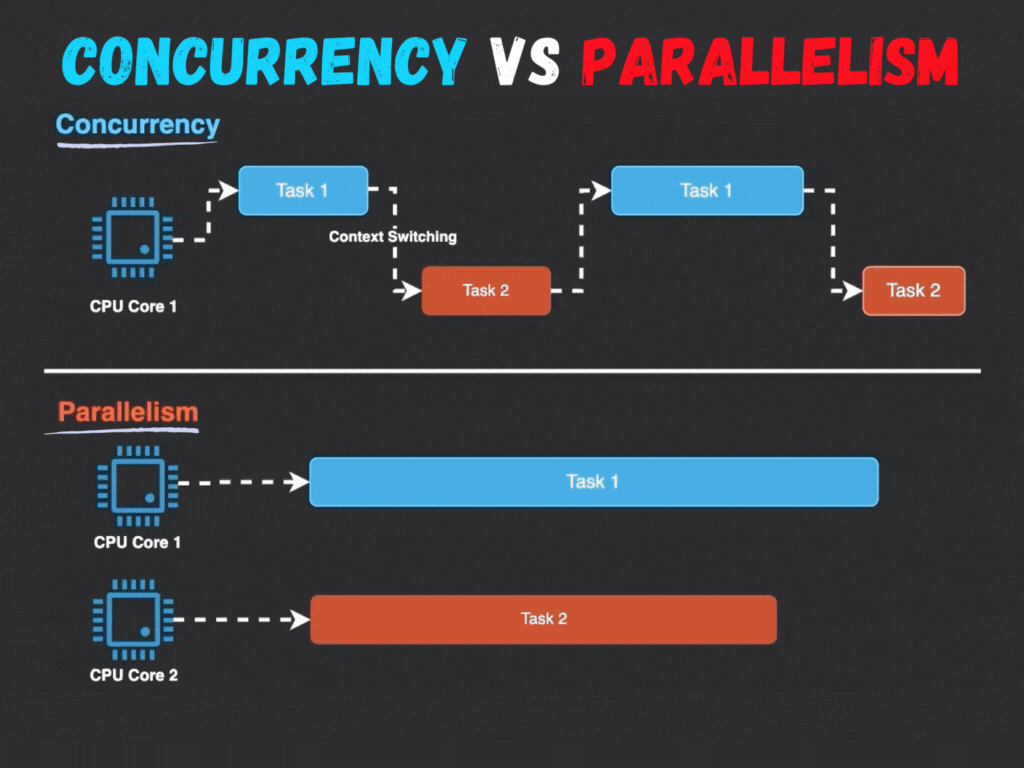

In [5]:
import time

In [6]:
def user_data_sync(user_id, delay=3):
    print(f"Fetching user data for user {user_id}")
    # delay
    time.sleep(delay)
    print(f"Finished getting data for user {user_id}")
    return {"user_id": user_id, "data": "some data"}

In [55]:
start = time.perf_counter()

user_id_list = [1, 2, 3]

for user_id in user_id_list:
    result = user_data_sync(user_id)
    print(result, end="\n\n")

end = time.perf_counter()

print(f"The total time is {end-start}")

Fetching user data for user 1
Finished getting data for user 1
{'user_id': 1, 'data': 'some data'}

Fetching user data for user 2
Finished getting data for user 2
{'user_id': 2, 'data': 'some data'}

Fetching user data for user 3
Finished getting data for user 3
{'user_id': 3, 'data': 'some data'}

The total time is 9.001202635000027


In [10]:
import asyncio

In [13]:
async def user_data(user_id, delay=3):
    print(f"Fetching user data for user {user_id}")
    # delay
    asyncio.sleep(delay)
    print(f"Finished getting data for user {user_id}")
    return {"user_id": user_id, "data": "some data"}

In [14]:
start = time.perf_counter()

user_id_list = [1, 2, 3]

for user_id in user_id_list:
    result = user_data(user_id)
    print(result, end="\n\n")

end = time.perf_counter()

print(f"The total time is {end-start}")

<coroutine object user_data at 0x7cf3726d9a80>

<coroutine object user_data at 0x7cf36b662dc0>

<coroutine object user_data at 0x7cf3726d9a80>

The total time is 0.0007976719998623594


<ipython-input-14-450408930a63>:6: RuntimeWarning: coroutine 'user_data' was never awaited
  result = user_data(user_id)
Exception ignored in: <coroutine object user_data at 0x7cf36bbaeb20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/google/colab/_variable_inspector.py", line 27, in run
KeyError: '__builtins__'
Exception ignored in: <coroutine object user_data at 0x7cf36bbaeb20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/google/colab/_variable_inspector.py", line 27, in run
KeyError: '__builtins__'


async   
Marks a function as asynchronous (or coroutine).

It tells Python: "This function might not run all at once; it can pause and come back later."

await  
Pauses the current async function until the thing we’re waiting for is done.

It tells Python: "Wait for this task to finish, but while waiting, allow other tasks to run."

You can only use await inside an async function.

In [15]:
async def my_function():
    # This is now an asynchronous function
    print("Hello")

In [19]:
coro = my_function()
coro

<coroutine object my_function at 0x7cf36b61a080>

In [21]:
# run method

# asyncio.run(coro)

In [22]:
await coro

Hello


In [23]:
await my_function()

Hello


In [51]:
async def user_data(user_id, delay=3):
    print(f"Fetching user data for user {user_id}")
    # delay
    await asyncio.sleep(delay)
    print(f"Finished getting data for user {user_id}")
    return {"user_id": user_id, "data": "some data"}

In [52]:
user_data(1)

<coroutine object user_data at 0x7cf3726d9a80>

In [53]:
await user_data(1)

Fetching user data for user 1
Finished getting data for user 1


{'user_id': 1, 'data': 'some data'}

In [54]:
start = time.perf_counter()

user_id_list = [1, 2, 3]

for user_id in user_id_list:
    result = await user_data(user_id)
    print(result, end="\n\n")

end = time.perf_counter()

print(f"The total time is {end-start}")

Fetching user data for user 1
Finished getting data for user 1
{'user_id': 1, 'data': 'some data'}

Fetching user data for user 2
Finished getting data for user 2
{'user_id': 2, 'data': 'some data'}

Fetching user data for user 3
Finished getting data for user 3
{'user_id': 3, 'data': 'some data'}

The total time is 9.011033440999654


In [56]:
# creating individual tasks

async def user_data(user_id, delay=3):
    print(f"Fetching user data for user {user_id}")
    # delay
    await asyncio.sleep(delay)
    print(f"Finished getting data for user {user_id}")
    return {"user_id": user_id, "data": "some data"}

In [69]:
async def main(user_list, delay_list):
    start = time.perf_counter()
    for user, delay in zip(user_list, delay_list):
        task = asyncio.create_task(user_data(user, delay))
        result = await task
        print(result)
    print(f"time taken was {time.perf_counter() - start}")

In [72]:
id_list = [1, 2, 3]

delay_list = [3, 1, 7]

In [73]:
await main(id_list, delay_list)

Fetching user data for user 1
Finished getting data for user 1
{'user_id': 1, 'data': 'some data'}
Fetching user data for user 2
Finished getting data for user 2
{'user_id': 2, 'data': 'some data'}
Fetching user data for user 3
Finished getting data for user 3
{'user_id': 3, 'data': 'some data'}
time taken was 11.012374916999761


In [ ]:
async def user_data(user_id, delay=3):
    print(f"Fetching user data for user {user_id}")
    # delay
    await asyncio.sleep(delay)
    print(f"Finished getting data for user {user_id}")
    return {"user_id": user_id, "data": "some data"}

In [74]:
async def main(user_list, delay_list):
    start = time.perf_counter()
    tasks = []
    for user, delay in zip(user_list, delay_list):
        task = asyncio.create_task(user_data(user, delay))
        tasks.append(task)

    results = []
    for task in tasks:
        results.append(await task)
    print(f"time taken was {time.perf_counter() - start}")

    return results

In [78]:
await main(id_list, delay_list)

Fetching user data for user 1
Fetching user data for user 2
Fetching user data for user 3
Finished getting data for user 3
Finished getting data for user 1
Finished getting data for user 2
time taken was 0.7009182860001602


[{'user_id': 1, 'data': 'some data'},
 {'user_id': 2, 'data': 'some data'},
 {'user_id': 3, 'data': 'some data'}]

In [77]:
id_list = [1, 2, 3]

delay_list = [0.5, 0.7, 0.2]

In [81]:
async def main(user_list, delay_list):
    start = time.perf_counter()
    results = await asyncio.gather(*[user_data(user_id, delay) for user_id, delay in zip(user_list, delay_list)])
    return results

In [83]:
await main(id_list, delay_list)

Fetching user data for user 1
Fetching user data for user 2
Fetching user data for user 3
Finished getting data for user 3
Finished getting data for user 1
Finished getting data for user 2


[{'user_id': 1, 'data': 'some data'},
 {'user_id': 2, 'data': 'some data'},
 {'user_id': 3, 'data': 'some data'}]